# 10_02 Classification Metrics: Precision, Recall, F1, MCC and Kappa

**Learning objectives**
- Compute the standard metrics from a confusion matrix: **accuracy, precision, recall (sensitivity), specificity, F1 and F$_\beta$, balanced accuracy, Youden's $J$, the Matthews correlation coefficient (MCC) and Cohen's kappa**, and write each as a function of $(\mathrm{TPR},\mathrm{FPR},\pi)$.
- Prove the **identities** $F_1=\frac{2TP}{2TP+FP+FN}$ (harmonic mean of precision and recall), $\mathrm{MCC}=\sqrt{J\cdot\text{markedness}}$ and the relation of kappa to chance agreement.
- Know which metrics **depend on the prevalence** and which do not, and see how the **best threshold differs from metric to metric**.
- Estimate the **uncertainty of a metric** by the bootstrap and know when "always predict positive" beats a real model on F1.

**Prerequisites:** [10_01 The confusion matrix](10_01_confusion_matrix_from_distributions.ipynb), [05_04 Bootstrap](../../module_05_sampling/notebooks/05_04_bootstrap.ipynb), [08_01 Entropy](../../module_08_information/notebooks/08_01_entropy_cross_entropy.ipynb) (log loss), [09_03 Naive Bayes](../../module_09_probabilistic_models/notebooks/09_03_naive_bayes.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap
From a confusion matrix with cells TP, FP, FN, TN: recall $=\frac{TP}{TP+FN}$, specificity $=\frac{TN}{TN+FP}$, precision $=\frac{TP}{TP+FP}$ (10_01). The **harmonic mean** of $a$ and $b$ is $\frac{2ab}{a+b}$; it is dominated by the smaller one. The **Pearson correlation** between two binary variables is the phi coefficient. Bootstrap resampling of the cases gives a sampling distribution of any statistic (05_04).

## 3. Intuition and story
A confusion matrix has four numbers; a decision needs one. The temptation is accuracy, but accuracy hides the trade-off (10_01). Different metrics answer different questions: **recall** asks "what share of the frauds did we catch?", **precision** "what share of our alerts were real?", **specificity** "what share of honest customers were left alone?". **F1** combines recall and precision into one number that is low if either is low; **MCC** is the correlation between prediction and truth and is high only if all four cells are good; **kappa** asks "how much better than chance agreement?". None is the right answer in general: each is a different way to weigh the same four cells, and they can rank two models differently. The skill is to know what each one rewards and ignores.

## 4. Formal definitions

With $P=TP+FN$ positives, $N=TN+FP$ negatives, $n=P+N$:

| Metric | Formula | Range | Depends on $\pi$? |
|---|---|---|---|
| Accuracy | $\dfrac{TP+TN}{n}$ | 0 to 1 | yes |
| Recall / TPR | $\dfrac{TP}{P}$ | 0 to 1 | no |
| Specificity / TNR | $\dfrac{TN}{N}$ | 0 to 1 | no |
| Precision / PPV | $\dfrac{TP}{TP+FP}$ | 0 to 1 | yes |
| **F1** | $\dfrac{2\,\mathrm{prec}\cdot\mathrm{rec}}{\mathrm{prec}+\mathrm{rec}}=\dfrac{2TP}{2TP+FP+FN}$ | 0 to 1 | yes |
| **F$_\beta$** | $\dfrac{(1+\beta^2)TP}{(1+\beta^2)TP+\beta^2FN+FP}$ | 0 to 1 | yes |
| Balanced accuracy | $\dfrac{\mathrm{TPR}+\mathrm{TNR}}{2}$ | 0 to 1 | no |
| Youden's $J$ (informedness) | $\mathrm{TPR}+\mathrm{TNR}-1$ | -1 to 1 | no |
| Markedness | $\mathrm{PPV}+\mathrm{NPV}-1$ | -1 to 1 | yes |
| **MCC** | $\dfrac{TP\cdot TN-FP\cdot FN}{\sqrt{(TP+FP)(TP+FN)(TN+FP)(TN+FN)}}=\sqrt{J\cdot\mathrm{markedness}}$ | -1 to 1 | yes |
| **Cohen's kappa** | $\dfrac{p_o-p_e}{1-p_e}$, $p_o=$ accuracy, $p_e=$ chance agreement | -1 to 1 | yes |

Chance agreement for kappa: $p_e=\frac{(TP+FP)(TP+FN)+(TN+FN)(TN+FP)}{n^2}$.

## 5. Derivations

### 5.1 F1 is the harmonic mean of precision and recall
With $p=\frac{TP}{TP+FP}$ and $r=\frac{TP}{TP+FN}$: $\frac{2pr}{p+r}=\frac{2\,TP^2/((TP+FP)(TP+FN))}{TP(2TP+FP+FN)/((TP+FP)(TP+FN))}=\frac{2TP}{2TP+FP+FN}$. **In plain words.** F1 ignores the true negatives completely and counts the two kinds of error equally; it is high only when both precision and recall are high, because the harmonic mean is close to the smaller of the two.

### 5.2 F$_\beta$ weighs recall $\beta$ times as much as precision
$F_\beta=\frac{(1+\beta^2)pr}{\beta^2p+r}$. $\beta=2$ favours recall (missing a case is worse than a false alarm), $\beta=0.5$ favours precision. **In plain words.** Choose $\beta$ so that one missed positive costs $\beta^2$ times as much as one false alarm.

### 5.3 MCC is the correlation of two binary variables
Treat prediction and truth as 0/1 variables: the Pearson correlation is the phi coefficient $\frac{TP\cdot TN-FP\cdot FN}{\sqrt{\cdots}}$. It factorises as $\mathrm{MCC}^2=J\cdot\text{markedness}$ with $J=\mathrm{TPR}-\mathrm{FPR}$ and markedness $=\mathrm{PPV}+\mathrm{NPV}-1$ (the correlation is the geometric mean of the two regression slopes). **In plain words.** MCC is 1 only for a perfect classifier, 0 for a coin flip or for "always the same answer", and it uses all four cells symmetrically.

### 5.4 Kappa corrects accuracy for chance
If prediction and truth were independent with the observed marginals, the expected agreement would be $p_e$ above. Kappa $=\frac{p_o-p_e}{1-p_e}$ is the share of the possible improvement over chance that the classifier achieves. For a trivial classifier that always predicts the majority class $p_o=p_e$ and kappa is 0. **In plain words.** A kappa of 0.4 means the classifier closes 40 % of the gap between guessing and perfection.

### 5.5 Prevalence dependence in closed form
With TPR, FPR fixed and prevalence $\pi$: $TP=\pi\,\mathrm{TPR}$, $FN=\pi(1-\mathrm{TPR})$, $FP=(1-\pi)\mathrm{FPR}$, $TN=(1-\pi)(1-\mathrm{FPR})$ (shares of all cases). Then $F_1=\frac{2\pi\mathrm{TPR}}{\pi(1+\mathrm{TPR})+(1-\pi)\mathrm{FPR}}$, which tends to $0$ as $\pi\to0$ (for FPR $>0$) and to $\frac{2\mathrm{TPR}}{1+\mathrm{TPR}}$ as $\pi\to1$; $J$ and balanced accuracy do not change. **In plain words.** A classifier does not become worse when positives become rare, but its F1, MCC and kappa fall, because precision falls.

### 5.6 A trivial baseline and the bootstrap
"Always positive": TPR = FPR = 1, so $F_1=\frac{2\pi}{1+\pi}$ (0.18 for $\pi=0.1$, 0.67 for $\pi=0.5$, 0.95 for $\pi=0.9$), while $J=0$, MCC $=0$ and kappa $=0$. The bootstrap resamples the $n$ cases with replacement, recomputes the metric and uses the percentile interval. **In plain words.** F1 alone can flatter a useless classifier when the positives are common; and every metric is a random variable that depends on how many positives were in the evaluation set.

## 6. Properties and relationships
- **Prevalence-invariant:** recall, specificity, balanced accuracy, $J$ (they condition on the true class); **prevalence-dependent:** precision, accuracy, F1, MCC, kappa.
- **Ranking disagreement:** two classifiers can be ordered differently by F1, MCC and $J$; the best threshold also differs (section 8.2).
- **F1 ignores TN:** adding a million easy negatives does not change it (good for detection problems, misleading when the negative class matters).
- **MCC is symmetric:** swapping the roles of the classes leaves it unchanged, unlike F1.
- **Micro, macro and weighted averages** extend these metrics to several classes (10_07).
- **Link to ML and AI:** the metrics reported for classifiers and for safety/toxicity filters, retrieval and RAG evaluation (precision/recall at $k$), NER and detection (F1), imbalanced benchmarks (MCC), annotator agreement (kappa) and the evaluation of LLM judges against human labels.

## 7. A metrics toolkit

All metrics from the four cells, plus the same as functions of $(\mathrm{TPR},\mathrm{FPR},\pi)$, so that the prevalence effect can be computed directly.

In [2]:
def metrics(tp, fp, fn, tn, beta=1.0):
    n = tp + fp + fn + tn; P = tp + fn; Nn = tn + fp; rec = tp / P if P else 0.0; spec = tn / Nn if Nn else 0.0; prec = tp / (tp + fp) if tp + fp else 0.0; npv = tn / (tn + fn) if tn + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0; fb = (1 + beta ** 2) * tp / ((1 + beta ** 2) * tp + beta ** 2 * fn + fp) if tp else 0.0
    den = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)); mcc = (tp * tn - fp * fn) / den if den > 0 else 0.0; po = (tp + tn) / n; pe = ((tp + fp) * (tp + fn) + (tn + fn) * (tn + fp)) / n ** 2; kappa = (po - pe) / (1 - pe) if pe < 1 else 0.0
    return dict(accuracy=po, recall=rec, specificity=spec, precision=prec, NPV=npv, F1=f1, Fbeta=fb, balanced_accuracy=(rec + spec) / 2, J=rec + spec - 1, markedness=prec + npv - 1, MCC=mcc, kappa=kappa)
def from_rates(tpr, fpr, pi, n=1_000_000): return metrics(n * pi * tpr, n * (1 - pi) * fpr, n * pi * (1 - tpr), n * (1 - pi) * (1 - fpr))
m1 = metrics(80, 40, 20, 860); print({k: round(float(v), 4) for k, v in m1.items()})
print("check F1 = 2 p r / (p + r):", 2 * m1["precision"] * m1["recall"] / (m1["precision"] + m1["recall"]), "| MCC^2 = J x markedness:", m1["MCC"] ** 2, m1["J"] * m1["markedness"])
assert abs(m1["F1"] - 2 * m1["precision"] * m1["recall"] / (m1["precision"] + m1["recall"])) < 1e-12 and abs(m1["MCC"] ** 2 - m1["J"] * m1["markedness"]) < 1e-12 and abs(m1["F1"] - 160 / 220) < 1e-12 and abs(m1["accuracy"] - 0.94) < 1e-12

{'accuracy': 0.94, 'recall': 0.8, 'specificity': 0.9556, 'precision': 0.6667, 'NPV': 0.9773, 'F1': 0.7273, 'Fbeta': 0.7273, 'balanced_accuracy': 0.8778, 'J': 0.7556, 'markedness': 0.6439, 'MCC': 0.6975, 'kappa': 0.6939}
check F1 = 2 p r / (p + r): 0.7272727272727272 | MCC^2 = J x markedness: 0.48653198653198654 0.4865319865319866


## 8. 2D visuals

### 8.1 Which classifiers do the metrics like? Maps over (FPR, TPR)
For prevalence 10 %: F1, MCC, accuracy and Youden's $J$ as functions of the operating point. Accuracy and F1 are high in the corner near the top-left but **accuracy is also high along the bottom-left** (flag nothing); MCC and $J$ are zero along the diagonal of random classifiers.

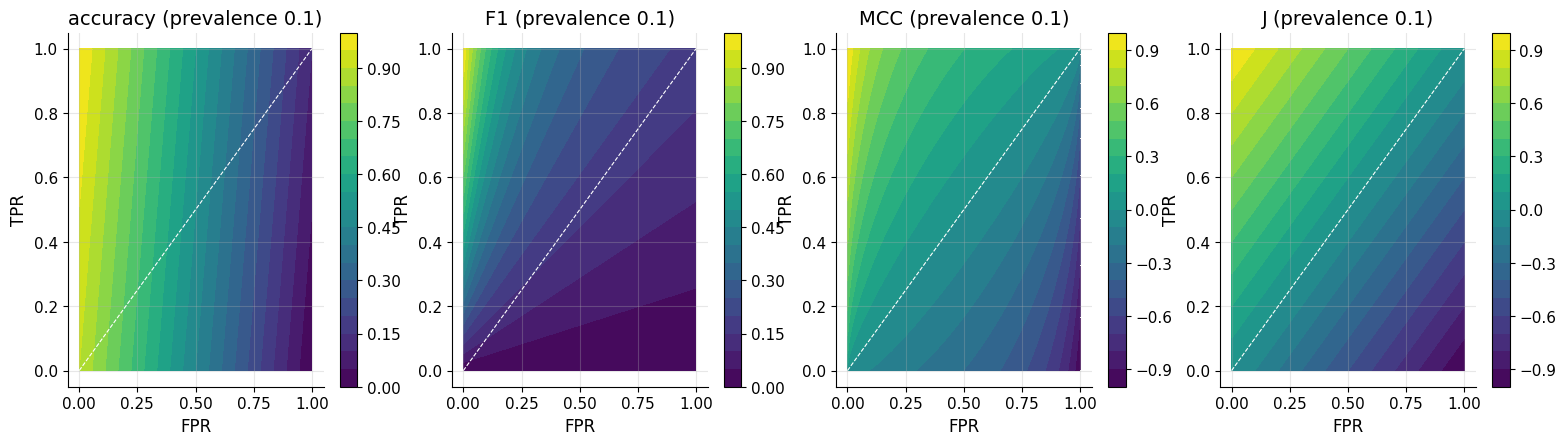

random classifier (TPR = FPR = 0.3): accuracy 0.660, F1 0.150, MCC 0.000, J 0.000


In [3]:
fg, tg = np.meshgrid(np.linspace(0.001, 0.999, 200), np.linspace(0.001, 0.999, 200)); pi = 0.10; mm = {k: np.zeros_like(fg) for k in ("accuracy", "F1", "MCC", "J")}
for i in range(200):
    for j in range(200): d = from_rates(tg[i, j], fg[i, j], pi, n=10_000); [mm[k].__setitem__((i, j), d[k]) for k in mm]
fig, axes = plt.subplots(1, 4, figsize=(19, 4.6))
for ax, (k, Z) in zip(axes, mm.items()): im = ax.contourf(fg, tg, Z, 20, cmap="viridis"); ax.plot([0, 1], [0, 1], "w--", linewidth=0.8); ax.set_title(f"{k} (prevalence {pi})"); ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); plt.colorbar(im, ax=ax)
plt.show(); print("random classifier (TPR = FPR = 0.3): accuracy %.3f, F1 %.3f, MCC %.3f, J %.3f" % tuple(from_rates(0.3, 0.3, pi)[k] for k in ("accuracy", "F1", "MCC", "J"))); assert abs(from_rates(0.3, 0.3, pi)["MCC"]) < 1e-6 and abs(from_rates(0.3, 0.3, pi)["J"]) < 1e-9 and from_rates(0.3, 0.3, pi)["F1"] > 0.1

### 8.2 The best threshold depends on the metric
For Gaussian scores ($d'=1.5$, prevalence 5 %) the metrics as functions of the threshold: each has its own maximum, so "the best threshold" is not defined until a metric (a cost) is chosen.

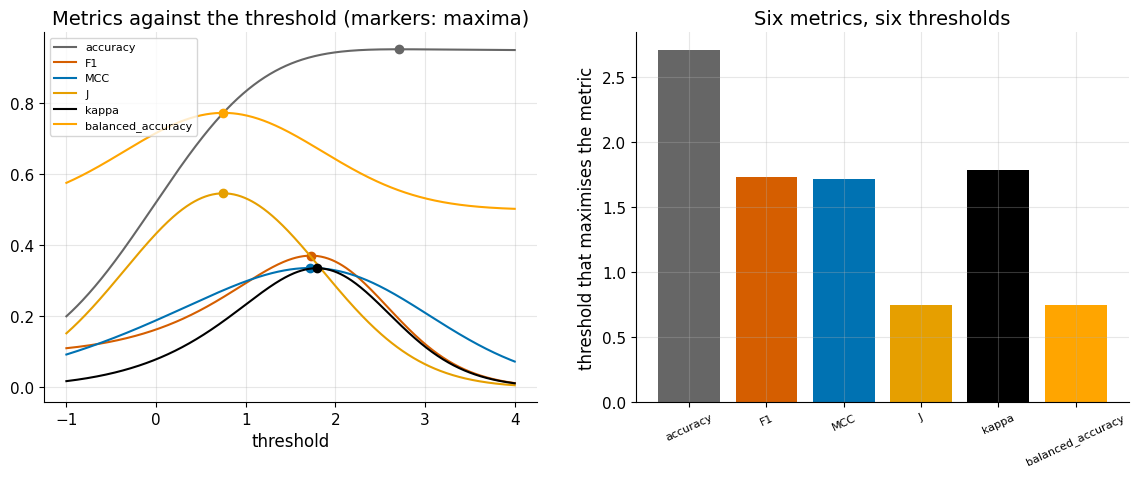

{'accuracy': (2.71, 0.952), 'F1': (1.73, 0.371), 'MCC': (1.72, 0.337), 'J': (0.75, 0.547), 'kappa': (1.79, 0.336), 'balanced_accuracy': (0.75, 0.773)}


In [4]:
ts = np.linspace(-1, 4, 501); pi2 = 0.05; rows = []
for t_ in ts: rows.append(from_rates(stats.norm.sf(t_, 1.5, 1), stats.norm.sf(t_, 0, 1), pi2, n=200_000))
df = pd.DataFrame(rows, index=ts); best = {k: (ts[df[k].argmax()], df[k].max()) for k in ("accuracy", "F1", "MCC", "J", "kappa", "balanced_accuracy")}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8)); cols = {"accuracy": NEUTRAL, "F1": HIGHLIGHT, "MCC": MAIN, "J": SIM, "kappa": "black", "balanced_accuracy": "orange"}
for k, c in cols.items(): axes[0].plot(ts, df[k], color=c, label=k); axes[0].plot(*best[k], "o", color=c)
axes[0].legend(fontsize=8); axes[0].set_xlabel("threshold"); axes[0].set_title("Metrics against the threshold (markers: maxima)")
axes[1].bar(range(6), [best[k][0] for k in cols], color=list(cols.values())); axes[1].set_xticks(range(6)); axes[1].set_xticklabels(list(cols), rotation=25, fontsize=8); axes[1].set_ylabel("threshold that maximises the metric"); axes[1].set_title("Six metrics, six thresholds")
plt.show(); print({k: (round(float(a), 2), round(float(b), 3)) for k, (a, b) in best.items()}); assert best["accuracy"][0] > best["F1"][0] > best["J"][0] and best["MCC"][0] > best["J"][0]

### 8.3 What happens to the metrics when the prevalence changes
The *same* classifier (TPR 0.85, FPR 0.10) evaluated at prevalences from 0.1 % to 90 %: recall, specificity, balanced accuracy and $J$ stay put, whereas precision, F1, MCC and kappa move a lot.

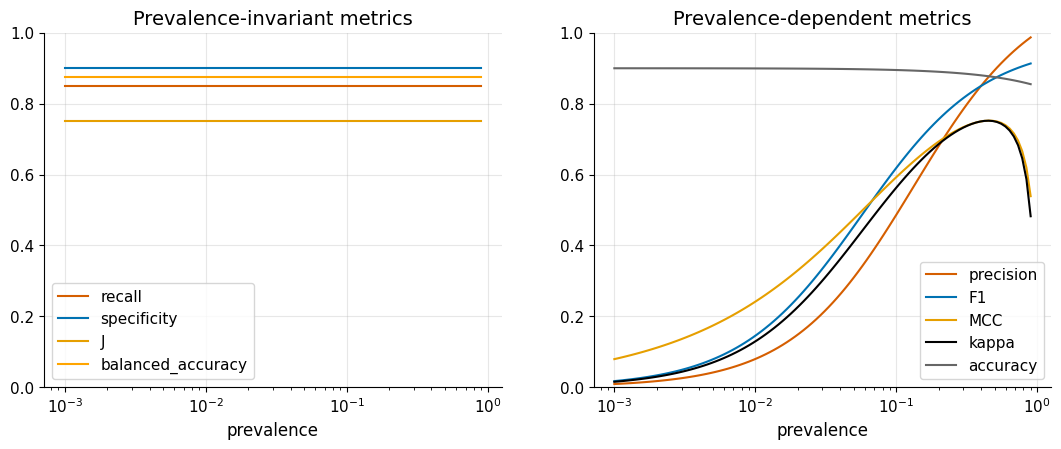

prevalence 1%: precision 0.082, F1 0.149, MCC 0.245, J 0.750 | prevalence 50%: precision 0.889, F1 0.869, MCC 0.752, J 0.750


In [5]:
pv = np.logspace(-3, np.log10(0.9), 100); rowsp = pd.DataFrame([from_rates(0.85, 0.10, p) for p in pv], index=pv); fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for k, c in [("recall", HIGHLIGHT), ("specificity", MAIN), ("J", SIM), ("balanced_accuracy", "orange")]: axes[0].semilogx(pv, rowsp[k], color=c, label=k)
axes[0].legend(); axes[0].set_title("Prevalence-invariant metrics"); axes[0].set_xlabel("prevalence"); axes[0].set_ylim(0, 1)
for k, c in [("precision", HIGHLIGHT), ("F1", MAIN), ("MCC", SIM), ("kappa", "black"), ("accuracy", NEUTRAL)]: axes[1].semilogx(pv, rowsp[k], color=c, label=k)
axes[1].legend(); axes[1].set_title("Prevalence-dependent metrics"); axes[1].set_xlabel("prevalence"); axes[1].set_ylim(0, 1)
plt.show(); r10 = rowsp.iloc[np.argmin(np.abs(pv - 0.01))]; r50 = rowsp.iloc[np.argmin(np.abs(pv - 0.5))]; print(f"prevalence 1%: precision {r10['precision']:.3f}, F1 {r10['F1']:.3f}, MCC {r10['MCC']:.3f}, J {r10['J']:.3f} | prevalence 50%: precision {r50['precision']:.3f}, F1 {r50['F1']:.3f}, MCC {r50['MCC']:.3f}, J {r50['J']:.3f}"); assert abs(rowsp["J"].max() - rowsp["J"].min()) < 1e-9 and r50["F1"] > 2 * r10["F1"]

## 9. 3D visuals

### 9.1 Static: F1 and MCC over (FPR, TPR)
Prevalence 10 %. Both surfaces rise towards the top-left corner (perfect classifier); the MCC is a saddle with zero along the diagonal, while F1 is positive everywhere along the top edge: a classifier that flags everything has F1 $=0.18$ here.

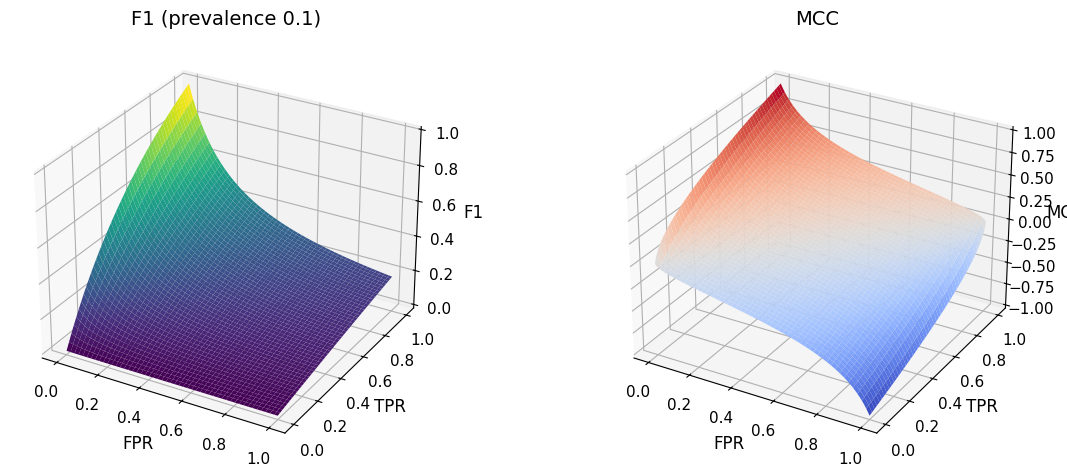

F1 of 'always positive' (TPR = FPR = 1) at prevalence 0.1: 0.1818 from the surface corner: 0.1818


In [6]:
fig = plt.figure(figsize=(14, 5.6)); ax = fig.add_subplot(1, 2, 1, projection="3d"); ax.plot_surface(fg, tg, mm["F1"], cmap="viridis", edgecolor="none"); ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.set_zlabel("F1"); ax.set_title("F1 (prevalence 0.1)"); ax.view_init(elev=28, azim=-60)
ax = fig.add_subplot(1, 2, 2, projection="3d"); ax.plot_surface(fg, tg, mm["MCC"], cmap="coolwarm", edgecolor="none"); ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.set_zlabel("MCC"); ax.set_title("MCC"); ax.view_init(elev=28, azim=-60)
plt.show(); print("F1 of 'always positive' (TPR = FPR = 1) at prevalence 0.1:", round(2 * 0.1 / 1.1, 4), "from the surface corner:", mm["F1"][-1, -1].round(4)); assert abs(mm["F1"][-1, -1] - 2 * 0.1 / 1.1) < 0.005 and mm["MCC"].max() > 0.9 and mm["MCC"].min() < -0.5

### 9.2 Interactive Plotly version of the MCC surface

In [7]:
fig = go.Figure(go.Surface(x=fg[0], y=tg[:, 0], z=mm["MCC"], colorscale="RdBu")); fig.update_layout(title="MCC over (FPR, TPR), prevalence 0.1", width=760, height=560, scene=dict(xaxis_title="FPR", yaxis_title="TPR", zaxis_title="MCC")); fig.show()

### 9.3 Static: F$_\beta$ over (threshold, $\beta$)
For $d'=1.5$ and prevalence 5 %: $\beta<1$ favours precision and moves the best threshold up, $\beta>1$ favours recall and moves it down.

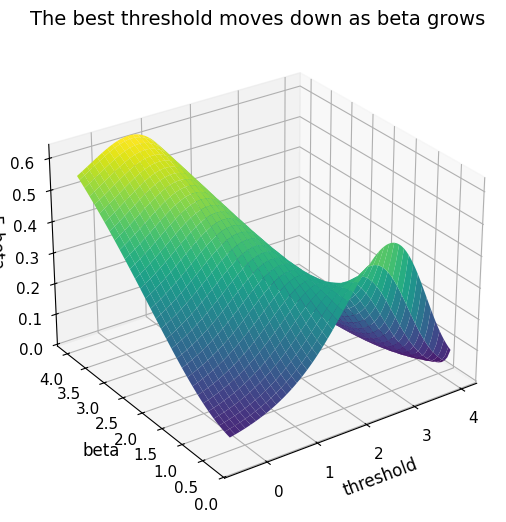

best threshold for beta = 0.5, 1, 2, 4: {0.5: 2.18, 1: 1.72, 2: 1.17, 4: 0.56}


In [8]:
tg3, bg3 = np.meshgrid(np.linspace(-0.5, 4, 90), np.linspace(0.25, 4, 60)); Fb = np.zeros_like(tg3)
for i in range(60):
    for j in range(90): tp_ = stats.norm.sf(tg3[i, j], 1.5, 1); fp_ = stats.norm.sf(tg3[i, j], 0, 1); TPs, FPs, FNs = pi2 * tp_, (1 - pi2) * fp_, pi2 * (1 - tp_); Fb[i, j] = (1 + bg3[i, j] ** 2) * TPs / ((1 + bg3[i, j] ** 2) * TPs + bg3[i, j] ** 2 * FNs + FPs)
fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(tg3, bg3, Fb, cmap="viridis", edgecolor="none"); ax.set_xlabel("threshold"); ax.set_ylabel("beta"); ax.set_zlabel("F_beta"); ax.set_title("The best threshold moves down as beta grows"); ax.view_init(elev=28, azim=-125)
plt.show(); bt = {b: tg3[0, np.argmax(Fb[np.argmin(np.abs(bg3[:, 0] - b))])] for b in (0.5, 1, 2, 4)}; print("best threshold for beta = 0.5, 1, 2, 4:", {k: round(float(v), 2) for k, v in bt.items()}); assert bt[0.5] > bt[1] > bt[2] > bt[4]

## 10. Simulation vs theory

### 10.1 MCC as a correlation and kappa from the margins
Simulate 200,000 cases from the Gaussian model (prevalence 5 %, threshold 1.2) and verify: the sample Pearson correlation of the two binary vectors equals the MCC; kappa computed from the cells equals the value from the formula $\frac{p_o-p_e}{1-p_e}$ computed from the margins; and MCC$^2=J\cdot$markedness.

In [9]:
g = np.random.default_rng(1); n = 200_000; y = (g.random(n) < 0.05).astype(int); s = np.where(y == 1, g.normal(1.5, 1, n), g.normal(0, 1, n)); pr = (s > 1.2).astype(int); tp, fp, fn, tn = [int(v) for v in (np.sum((pr == 1) & (y == 1)), np.sum((pr == 1) & (y == 0)), np.sum((pr == 0) & (y == 1)), np.sum((pr == 0) & (y == 0)))]; mt = metrics(tp, fp, fn, tn)
pe = (pr.mean() * y.mean() + (1 - pr.mean()) * (1 - y.mean())); kap = (np.mean(pr == y) - pe) / (1 - pe)
print(f"MCC {mt['MCC']:.5f} | Pearson correlation of the binary vectors {np.corrcoef(pr, y)[0, 1]:.5f} | kappa {mt['kappa']:.5f} vs from the margins {kap:.5f} | MCC^2 {mt['MCC'] ** 2:.5f} vs J x markedness {mt['J'] * mt['markedness']:.5f}")
th = from_rates(stats.norm.sf(1.2, 1.5, 1), stats.norm.sf(1.2), 0.05); print(f"theory: MCC {th['MCC']:.4f}, F1 {th['F1']:.4f}, J {th['J']:.4f}, kappa {th['kappa']:.4f} | simulation: MCC {mt['MCC']:.4f}, F1 {mt['F1']:.4f}, J {mt['J']:.4f}, kappa {mt['kappa']:.4f}")
assert abs(mt["MCC"] - np.corrcoef(pr, y)[0, 1]) < 1e-9 and abs(mt["kappa"] - kap) < 1e-9 and abs(mt["MCC"] - th["MCC"]) < 0.01 and abs(mt["F1"] - th["F1"]) < 0.01

MCC 0.31941 | Pearson correlation of the binary vectors 0.31941 | kappa 0.27399 vs from the margins 0.27399 | MCC^2 0.10202 vs J x markedness 0.10202
theory: MCC 0.3156, F1 0.3249, J 0.5028, kappa 0.2711 | simulation: MCC 0.3194, F1 0.3274, J 0.5100, kappa 0.2740


### 10.2 Metrics are random variables
With few positives the F1, MCC and recall of one evaluation set vary widely: for a classifier with TPR 0.8 and FPR 0.05, prevalence 5 %, the spread of each metric over 2,000 evaluation sets of $n=200,1000,5000$.

In [10]:
g = np.random.default_rng(2); rows = []
for n_ in (200, 1000, 5000):
    vals = {"recall": [], "precision": [], "F1": [], "MCC": []}
    for _ in range(2000):
        y_ = g.random(n_) < 0.05; p_ = np.where(y_, g.random(n_) < 0.8, g.random(n_) < 0.05); mm_ = metrics(np.sum(p_ & y_), np.sum(p_ & ~y_), np.sum(~p_ & y_), np.sum(~p_ & ~y_)); [vals[k].append(mm_[k]) for k in vals]
    th_ = from_rates(0.8, 0.05, 0.05); rows.append((n_, th_["F1"], np.mean(vals["F1"]), np.std(vals["F1"]), th_["MCC"], np.mean(vals["MCC"]), np.std(vals["MCC"]), np.std(vals["recall"])))
tb = pd.DataFrame(rows, columns=["n", "F1 (theory)", "F1 mean", "F1 SD", "MCC (theory)", "MCC mean", "MCC SD", "recall SD"]); print(tb.round(4).to_string(index=False)); assert tb["F1 SD"].is_monotonic_decreasing and abs(tb["F1 mean"].iloc[-1] - tb["F1 (theory)"].iloc[-1]) < 0.01 and tb["recall SD"].iloc[0] > 0.1

   n  F1 (theory)  F1 mean  F1 SD  MCC (theory)  MCC mean  MCC SD  recall SD
 200       0.5818   0.5741 0.1181        0.5785    0.5761  0.1150     0.1348
1000       0.5818   0.5819 0.0499        0.5785    0.5797  0.0488     0.0578
5000       0.5818   0.5810 0.0224        0.5785    0.5778  0.0219     0.0256


## 11. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
print("from cells: f1 = 2 * tp / (2 * tp + fp + fn) | mcc = (tp * tn - fp * fn) / sqrt((tp + fp)(tp + fn)(tn + fp)(tn + fn)) | kappa = (po - pe) / (1 - pe) | J = recall + specificity - 1")
print("library equivalents: sklearn.metrics.f1_score, fbeta_score, matthews_corrcoef, cohen_kappa_score, balanced_accuracy_score, precision_recall_fscore_support, classification_report")
print("bootstrap interval: idx = rng.integers(0, n, n); metric(y[idx], pred[idx]) repeated, then np.quantile(vals, [0.025, 0.975])")
print("check: precision 0.667, recall 0.8 -> F1", round(2 * 0.667 * 0.8 / (0.667 + 0.8), 4), "= 2 TP / (2 TP + FP + FN) for TP = 80, FP = 40, FN = 20:", round(160 / 220, 4), "| phi coefficient via stats: ", round(float(stats.pearsonr([1, 1, 0, 0, 1, 0], [1, 0, 0, 0, 1, 1])[0]), 4))
assert abs(2 * 0.667 * 0.8 / (0.667 + 0.8) - 160 / 220) < 1e-3

from cells: f1 = 2 * tp / (2 * tp + fp + fn) | mcc = (tp * tn - fp * fn) / sqrt((tp + fp)(tp + fn)(tn + fp)(tn + fn)) | kappa = (po - pe) / (1 - pe) | J = recall + specificity - 1
library equivalents: sklearn.metrics.f1_score, fbeta_score, matthews_corrcoef, cohen_kappa_score, balanced_accuracy_score, precision_recall_fscore_support, classification_report
bootstrap interval: idx = rng.integers(0, n, n); metric(y[idx], pred[idx]) repeated, then np.quantile(vals, [0.025, 0.975])
check: precision 0.667, recall 0.8 -> F1 0.7275 = 2 TP / (2 TP + FP + FN) for TP = 80, FP = 40, FN = 20: 0.7273 | phi coefficient via stats:  0.3333


## 12. Real-world worked examples

---
### Example 1 (main): two churn models, five metrics

**Scenario.** A telecom wants to predict which of 10,000 customers will leave (prevalence 8 %, so 800 churners). **Model A** is aggressive: it flags 2,000 customers and catches 640 churners. **Model B** is cautious: it flags 900 customers and catches 480 churners.

**Questions**
1. Build the confusion matrix of each model and compute accuracy, recall, specificity, precision, F1, F$_2$, balanced accuracy, $J$, MCC and kappa.
2. Which model do the different metrics prefer?
3. Which prefers each model if a retained customer is worth 100 and a retention offer costs 10 (and an unnecessary offer is also 10)?

### 12.1 By hand
Model A: TP 640, FP $2000-640=1360$, FN $800-640=160$, TN $9200-1360=7840$. Recall $=0.80$, precision $=0.32$, F1 $=1280/(1280+1360+160)=0.457$, accuracy $=(640+7840)/10{,}000=0.848$. Model B: TP 480, FP 420, FN 320, TN 8780: recall 0.60, precision 0.533, F1 $=960/(960+420+320)=0.565$, accuracy 0.926. So accuracy and F1 prefer B, while recall prefers A; a cost-based view (question 3) decides.

In [12]:
mA = metrics(640, 1360, 160, 7840, beta=2); mB = metrics(480, 420, 320, 8780, beta=2); tb1 = pd.DataFrame({"Model A (flags 2,000)": mA, "Model B (flags 900)": mB}); print(tb1.round(4).to_string())
pref = {k: ("A" if mA[k] > mB[k] else "B") for k in ("accuracy", "recall", "specificity", "precision", "F1", "Fbeta", "balanced_accuracy", "J", "MCC", "kappa")}; print("Q2: preferred model by metric:", pref)
def profit(tp, fp): return tp * (100 - 10) - fp * 10
print(f"Q3: profit with a retention value of 100 and an offer cost of 10: A {profit(640, 1360):,}, B {profit(480, 420):,} (no offers at all: 0)")

                   Model A (flags 2,000)  Model B (flags 900)
accuracy                          0.8480               0.9260
recall                            0.8000               0.6000
specificity                       0.8522               0.9543
precision                         0.3200               0.5333
NPV                               0.9800               0.9648
F1                                0.4571               0.5647
Fbeta                             0.6154               0.5854
balanced_accuracy                 0.8261               0.7772
J                                 0.6522               0.5543
markedness                        0.3000               0.4982
MCC                               0.4423               0.5255
kappa                             0.3871               0.5244
Q2: preferred model by metric: {'accuracy': 'B', 'recall': 'A', 'specificity': 'B', 'precision': 'B', 'F1': 'B', 'Fbeta': 'A', 'balanced_accuracy': 'A', 'J': 'A', 'MCC': 'B', 'kappa': 'B'}
Q3: p

### 12.2 Asserts

In [13]:
assert abs(mA["F1"] - 1280 / 2800) < 1e-12 and abs(mB["F1"] - 960 / 1700) < 1e-12 and abs(mA["accuracy"] - 0.848) < 1e-12 and pref["accuracy"] == "B" and pref["recall"] == "A" and pref["F1"] == "B" and profit(640, 1360) > profit(480, 420)
print("all checks passed")

all checks passed


### 12.3 Verify by simulation
Generate the two models' decisions from score models with the same TPR/FPR, 1,000 evaluation sets of 10,000 customers, and check that the metric values and their ranking are stable.

In [14]:
g = np.random.default_rng(5); res = {"A": [], "B": []}
for _ in range(1000):
    y_ = g.random(10_000) < 0.08; a_ = np.where(y_, g.random(10_000) < 0.8, g.random(10_000) < 1360 / 9200); b_ = np.where(y_, g.random(10_000) < 0.6, g.random(10_000) < 420 / 9200); res["A"].append(metrics(np.sum(a_ & y_), np.sum(a_ & ~y_), np.sum(~a_ & y_), np.sum(~a_ & ~y_))); res["B"].append(metrics(np.sum(b_ & y_), np.sum(b_ & ~y_), np.sum(~b_ & y_), np.sum(~b_ & ~y_)))
for k in ("F1", "MCC", "J"): a, b = np.array([r[k] for r in res["A"]]), np.array([r[k] for r in res["B"]]); print(f"{k}: A {a.mean():.4f} +/- {a.std():.4f}, B {b.mean():.4f} +/- {b.std():.4f}, share of evaluation sets where A beats B: {np.mean(a > b):.3f}")
assert abs(np.mean([r["F1"] for r in res["B"]]) - mB["F1"]) < 0.01

F1: A 0.4564 +/- 0.0115, B 0.5645 +/- 0.0145, share of evaluation sets where A beats B: 0.000
MCC: A 0.4416 +/- 0.0113, B 0.5255 +/- 0.0154, share of evaluation sets where A beats B: 0.000
J: A 0.6512 +/- 0.0142, B 0.5547 +/- 0.0171, share of evaluation sets where A beats B: 1.000


### 12.4 Plots

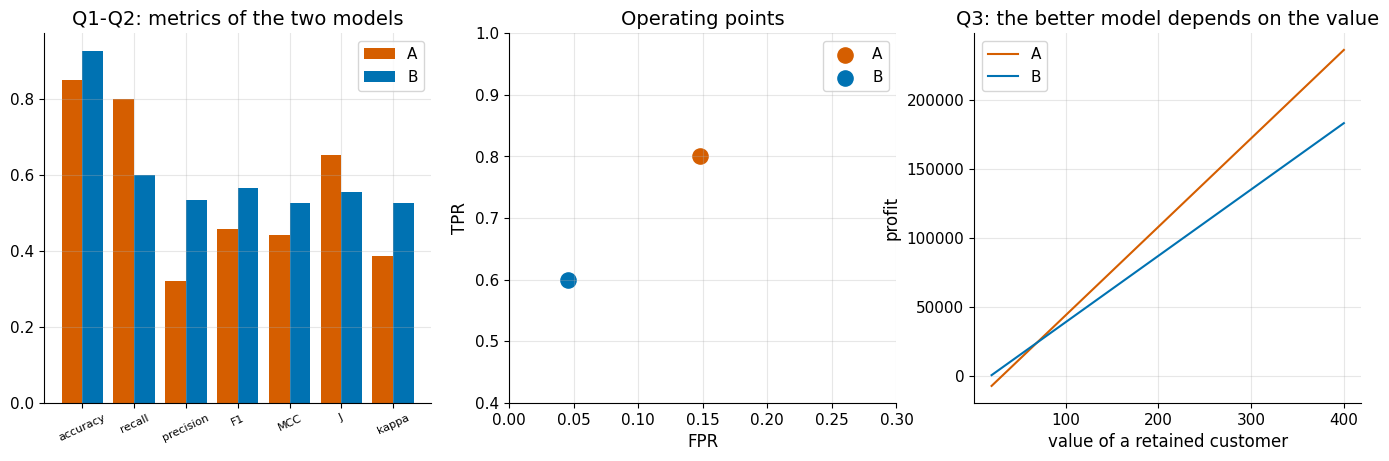

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8)); ks = ["accuracy", "recall", "precision", "F1", "MCC", "J", "kappa"]; x = np.arange(len(ks)); axes[0].bar(x - 0.2, [mA[k] for k in ks], 0.4, color=HIGHLIGHT, label="A"); axes[0].bar(x + 0.2, [mB[k] for k in ks], 0.4, color=MAIN, label="B"); axes[0].set_xticks(x); axes[0].set_xticklabels(ks, rotation=25, fontsize=8); axes[0].legend(); axes[0].set_title("Q1-Q2: metrics of the two models")
for nm, (tp, fp, fn, tn), c in [("A", (640, 1360, 160, 7840), HIGHLIGHT), ("B", (480, 420, 320, 8780), MAIN)]: axes[1].scatter([fp / (fp + tn)], [tp / (tp + fn)], s=120, color=c, label=nm)
axes[1].plot([0, 1], [0, 1], color=NEUTRAL, linestyle=":"); axes[1].set_xlim(0, 0.3); axes[1].set_ylim(0.4, 1); axes[1].legend(); axes[1].set_xlabel("FPR"); axes[1].set_ylabel("TPR"); axes[1].set_title("Operating points")
vr = np.linspace(20, 400, 100); axes[2].plot(vr, [profit(640, 1360) - 0 * v + 640 * (v - 100) for v in vr], color=HIGHLIGHT, label="A"); axes[2].plot(vr, [profit(480, 420) + 480 * (v - 100) for v in vr], color=MAIN, label="B"); axes[2].legend(); axes[2].set_xlabel("value of a retained customer"); axes[2].set_ylabel("profit"); axes[2].set_title("Q3: the better model depends on the value")
plt.show()

### 12.5 Interpretation and decision (Example 1)
- Model A (flags 2,000) has recall **0.80**, precision **0.32**, F1 **0.457**, MCC **0.442**, kappa **0.387**, accuracy **0.848**; Model B (flags 900) has recall **0.60**, precision **0.533**, F1 **0.565**, MCC **0.526**, kappa **0.524**, accuracy **0.926**.
- **The metrics disagree:** accuracy, precision, F1, MCC and kappa prefer B; recall, balanced accuracy, Youden's $J$ (0.652 against 0.554) and F$_2$ (0.615 against 0.585) prefer A. 1,000 simulated evaluation sets confirm that the ranking is not noise: B beats A on F1 and MCC in every set, A beats B on $J$ in every set.
- With a retained customer worth 100 and an offer costing 10 the profit is **44,000 for A against 39,000 for B**: the aggressive model wins because a missed churner costs far more than a wasted offer, even though its F1 is lower.
- **Decision.** Choose the metric from the costs, not the other way round: when a miss is 9 times as costly as a false alarm, recall-weighted metrics (F$_2$, $J$) or an explicit profit calculation agree with the business; F1 and accuracy do not.

---
### Example 2: trivial baselines (F1 can flatter a useless model)

**Scenario.** For prevalences 1 %, 10 %, 50 % and 90 % compare three classifiers: always negative, always positive, and a real classifier with TPR 0.80 and FPR 0.20.

**Questions.** (1) Accuracy, F1, MCC, kappa and $J$ for each. (2) For which prevalences does "always positive" beat the real classifier on F1? (3) Which metrics expose the baselines?

In [16]:
rows = {}
for p in (0.01, 0.10, 0.50, 0.90):
    for nm, (tpr, fpr) in {"always negative": (0.0, 0.0), "always positive": (1.0, 1.0), "real (TPR 0.8, FPR 0.2)": (0.8, 0.2)}.items(): d = from_rates(tpr, fpr, p); rows[(p, nm)] = {k: d[k] for k in ("accuracy", "F1", "MCC", "kappa", "J")}
tb2 = pd.DataFrame(rows).T; print(tb2.round(3).to_string()); win = [p for p in (0.01, 0.10, 0.50, 0.90) if tb2.loc[(p, "always positive"), "F1"] > tb2.loc[(p, "real (TPR 0.8, FPR 0.2)"), "F1"]]; print("Q2: prevalences where 'always positive' beats the real classifier on F1:", win)

                              accuracy     F1    MCC  kappa    J
0.01 always negative              0.99  0.000  0.000  0.000  0.0
     always positive              0.01  0.020  0.000  0.000  0.0
     real (TPR 0.8, FPR 0.2)      0.80  0.074  0.148  0.056  0.6
0.10 always negative              0.90  0.000  0.000  0.000  0.0
     always positive              0.10  0.182  0.000  0.000  0.0
     real (TPR 0.8, FPR 0.2)      0.80  0.444  0.410  0.351  0.6
0.50 always negative              0.50  0.000  0.000  0.000  0.0
     always positive              0.50  0.667  0.000  0.000  0.0
     real (TPR 0.8, FPR 0.2)      0.80  0.800  0.600  0.600  0.6
0.90 always negative              0.10  0.000  0.000  0.000  0.0
     always positive              0.90  0.947  0.000  0.000  0.0
     real (TPR 0.8, FPR 0.2)      0.80  0.878  0.410  0.351  0.6
Q2: prevalences where 'always positive' beats the real classifier on F1: [0.9]


### 12.5 Asserts

In [17]:
assert abs(tb2.loc[(0.10, "always positive"), "F1"] - 2 * 0.1 / 1.1) < 1e-9 and abs(tb2.loc[(0.9, "always positive"), "F1"] - 2 * 0.9 / 1.9) < 1e-9 and win == [0.9] and all(abs(tb2.loc[(p, nm), k]) < 1e-9 for p in (0.01, 0.1, 0.5, 0.9) for nm in ("always negative", "always positive") for k in ("MCC", "kappa", "J")) and tb2.loc[(0.01, "always negative"), "accuracy"] > tb2.loc[(0.01, "real (TPR 0.8, FPR 0.2)"), "accuracy"]
print("all checks passed")

all checks passed


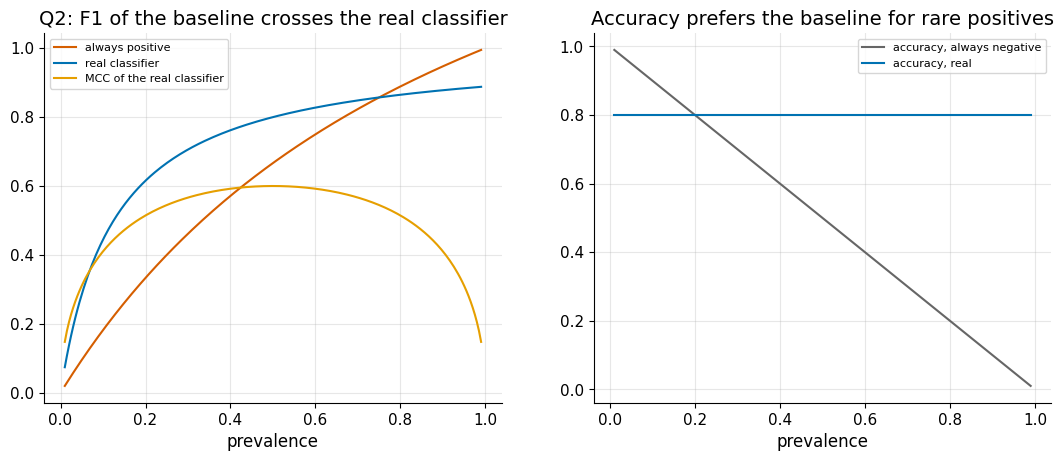

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); pp = np.linspace(0.01, 0.99, 200); axes[0].plot(pp, [from_rates(1, 1, p)["F1"] for p in pp], color=HIGHLIGHT, label="always positive"); axes[0].plot(pp, [from_rates(0.8, 0.2, p)["F1"] for p in pp], color=MAIN, label="real classifier"); axes[0].plot(pp, [from_rates(0.8, 0.2, p)["MCC"] for p in pp], color=SIM, label="MCC of the real classifier"); axes[0].legend(fontsize=8); axes[0].set_xlabel("prevalence"); axes[0].set_title("Q2: F1 of the baseline crosses the real classifier")
axes[1].plot(pp, [from_rates(0, 0, p)["accuracy"] for p in pp], color=NEUTRAL, label="accuracy, always negative"); axes[1].plot(pp, [from_rates(0.8, 0.2, p)["accuracy"] for p in pp], color=MAIN, label="accuracy, real"); axes[1].legend(fontsize=8); axes[1].set_xlabel("prevalence"); axes[1].set_title("Accuracy prefers the baseline for rare positives")
plt.show()

### 12.6 Interpretation and decision (Example 2)
- "Always positive" has F1 **0.020** at prevalence 1 %, **0.182** at 10 %, **0.667** at 50 % and **0.947** at 90 %, i.e. $2\pi/(1+\pi)$, while its MCC, kappa and $J$ are exactly **0**.
- The real classifier (TPR 0.8, FPR 0.2) has F1 0.074, 0.444, 0.800 and 0.878 at the same prevalences, so the useless baseline **beats it on F1 only at 90 %**; its MCC is 0.148, 0.410, 0.600 and 0.410 and $J=0.6$ throughout.
- At 1 % prevalence "always negative" has an accuracy of **0.99** against **0.80** for the real classifier.
- **Decision.** Always report a trivial baseline next to a model; use MCC, kappa or $J$ (zero for any constant classifier) when the classes are very unbalanced, and distrust an F1 on a dataset where positives are the majority.

---
### Example 3: the best threshold for each metric

**Scenario.** Gaussian scores with $d'=1.5$ and prevalence 5 % (the setting of 8.2). Find the threshold that maximises each of accuracy, F1, MCC, balanced accuracy ($J$), kappa and F$_2$, and the value of every metric at each of those thresholds.

**Questions.** (1) The six optimal thresholds and the resulting recall, FPR and precision. (2) How much of the best F1 do we lose if we optimise accuracy instead? (3) Which metrics agree on the threshold?

In [19]:
ts = np.linspace(-1, 4, 2001); rowsT = [from_rates(stats.norm.sf(t_, 1.5, 1), stats.norm.sf(t_, 0, 1), 0.05, n=200_000) for t_ in ts]; dfT = pd.DataFrame(rowsT, index=ts)
fb2 = [(1 + 4) * stats.norm.sf(t_, 1.5, 1) * 0.05 / ((1 + 4) * stats.norm.sf(t_, 1.5, 1) * 0.05 + 4 * 0.05 * stats.norm.cdf(t_, 1.5, 1) + 0.95 * stats.norm.sf(t_)) for t_ in ts]; dfT["F2"] = fb2
opt = {k: dfT[k].idxmax() for k in ("accuracy", "F1", "MCC", "J", "kappa", "F2")}; tb3 = pd.DataFrame({k: {"threshold": t_, "recall": stats.norm.sf(t_, 1.5, 1), "FPR": stats.norm.sf(t_), "precision": dfT.loc[t_, "precision"], "F1": dfT.loc[t_, "F1"], "accuracy": dfT.loc[t_, "accuracy"], "MCC": dfT.loc[t_, "MCC"]} for k, t_ in opt.items()}).T; print("Q1:"); print(tb3.round(3).to_string())
print(f"Q2: best F1 {dfT['F1'].max():.4f}; F1 at the accuracy-optimal threshold {dfT.loc[opt['accuracy'], 'F1']:.4f} ({1 - dfT.loc[opt['accuracy'], 'F1'] / dfT['F1'].max():.1%} lost); accuracy at the F1-optimal threshold {dfT.loc[opt['F1'], 'accuracy']:.4f} vs best {dfT['accuracy'].max():.4f}")

Q1:
          threshold  recall    FPR  precision     F1  accuracy    MCC
accuracy      2.712   0.113  0.003      0.640  0.192     0.952  0.255
F1            1.728   0.410  0.042      0.339  0.371     0.931  0.337
MCC           1.723   0.412  0.042      0.338  0.371     0.930  0.337
J             0.750   0.773  0.227      0.152  0.254     0.773  0.274
kappa         1.792   0.385  0.037      0.357  0.370     0.935  0.336
F2            1.178   0.626  0.119      0.216  0.322     0.868  0.314
Q2: best F1 0.3713; F1 at the accuracy-optimal threshold 0.1916 (48.4% lost); accuracy at the F1-optimal threshold 0.9306 vs best 0.9525


### 12.6 Asserts

In [20]:
assert opt["accuracy"] > opt["F1"] and opt["F1"] > opt["F2"] and opt["MCC"] > opt["J"] and dfT.loc[opt["accuracy"], "F1"] < dfT["F1"].max() and abs(opt["J"] - 0.75) < 0.01
print("all checks passed")

all checks passed


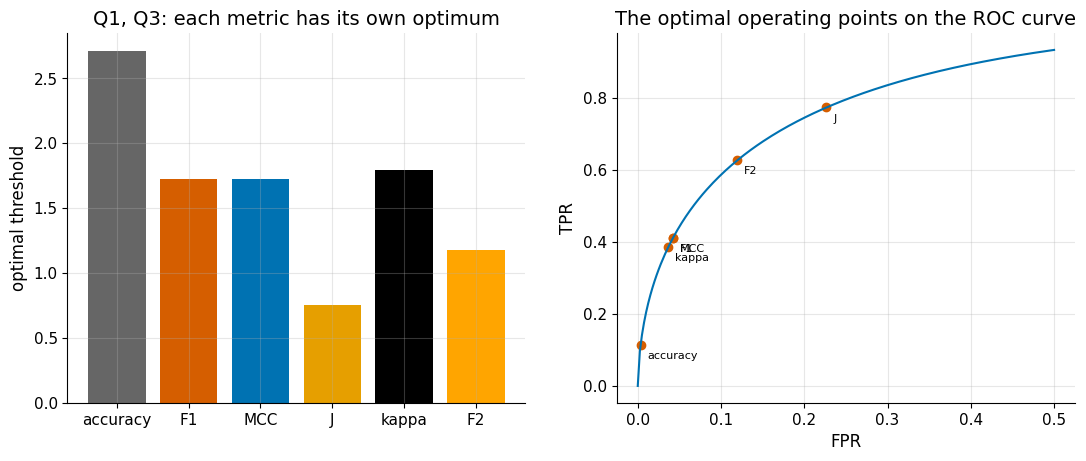

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); names = list(opt); axes[0].bar(names, [opt[k] for k in names], color=[NEUTRAL, HIGHLIGHT, MAIN, SIM, "black", "orange"]); axes[0].set_ylabel("optimal threshold"); axes[0].set_title("Q1, Q3: each metric has its own optimum")
axes[1].plot(tb3["FPR"], tb3["recall"], "o", color=HIGHLIGHT); [axes[1].annotate(k, (tb3.loc[k, "FPR"], tb3.loc[k, "recall"]), xytext=(5, -10), textcoords="offset points", fontsize=8) for k in names]; fgr = np.linspace(0, 0.5, 200); axes[1].plot(fgr, stats.norm.sf(stats.norm.isf(fgr) - 1.5), color=MAIN); axes[1].set_xlabel("FPR"); axes[1].set_ylabel("TPR"); axes[1].set_title("The optimal operating points on the ROC curve")
plt.show()

### 12.7 Interpretation and decision (Example 3)
- At prevalence 5 % and $d'=1.5$ the optimal thresholds are **2.71** for accuracy (recall only 0.11), **1.73** for F1, **1.72** for MCC, **1.79** for kappa, **1.18** for F$_2$ and **0.75** for $J$ (recall 0.77, FPR 0.23, precision 0.15).
- Optimising accuracy gives an F1 of **0.19** against the best **0.371**, a loss of **48 %**, while optimising F1 costs only 2.2 points of accuracy (0.931 against 0.952).
- F1, MCC and kappa agree closely (1.72 to 1.79) because they all punish both kinds of error through precision; accuracy, F$_2$ and $J$ sit far away on either side.
- **Decision.** Fix the metric (ideally a cost) before tuning the threshold; a threshold tuned for accuracy on rare positives produces a model that nearly never fires.

---
### Example 4: how uncertain is an F1? (bootstrap on real SMS spam)

**Scenario.** The naive Bayes spam filter of 09_03 on the held-out part of the SMS Spam Collection (1,115 messages, 141 spam) at threshold 0. We compute its metrics and **bootstrap confidence intervals**, then check what happens with a subsample of only 200 messages.

**Questions.** (1) The metrics and their 95 % bootstrap intervals. (2) How do the intervals widen for a 200-message subsample (about 25 spam)? (3) Does the bootstrap interval for F1 cover the "true" value (the F1 on the whole population of 5,574 messages, scored with the same model, as a stand-in) in repeated subsamples?

In [22]:
import re
from collections import Counter
from scipy import sparse
raw = pd.read_csv("../../module_09_probabilistic_models/data/SMSSpamCollection.tsv", sep="\t", header=None, names=["label", "text"], encoding="utf-8", quoting=3); y_all = (raw["label"] == "spam").astype(int).to_numpy(); texts = raw["text"].tolist(); tok = lambda s: re.findall(r"[a-z0-9']+|[£$!?]", s.lower())
g = np.random.default_rng(0); perm = g.permutation(len(texts)); ntr = int(0.8 * len(texts)); itr, ite = perm[:ntr], perm[ntr:]; cnt = Counter(w for i in itr for w in tok(texts[i])); vocab = {w: k for k, (w, c) in enumerate(sorted((w, c) for w, c in cnt.items() if c >= 2))}; V = len(vocab)
def bow(idx):
    rows, cols, vals = [], [], []
    for r, i in enumerate(idx):
        for w, c in Counter(tok(texts[i])).items():
            if w in vocab: rows.append(r); cols.append(vocab[w]); vals.append(c)
    return sparse.csr_matrix((vals, (rows, cols)), shape=(len(idx), V), dtype=float)
Xtr, Xte = bow(itr), bow(ite); ytr, yte = y_all[itr], y_all[ite]; fc = np.vstack([np.asarray(Xtr[ytr == c].sum(axis=0)).ravel() for c in (0, 1)]); lt = np.log((fc + 1) / (fc.sum(axis=1, keepdims=True) + V)); sc = np.asarray(Xte @ (lt[1] - lt[0])).ravel() + np.log(ytr.mean() / (1 - ytr.mean())); pred = sc > 0
def cells(y, p): return int(np.sum(p & (y == 1))), int(np.sum(p & (y == 0))), int(np.sum(~p & (y == 1))), int(np.sum(~p & (y == 0)))
base = metrics(*cells(yte, pred)); ks = ("accuracy", "recall", "precision", "F1", "MCC", "kappa")
def boot(y, p, B=2000, seed=0):
    g = np.random.default_rng(seed); out = {k: [] for k in ks}
    for _ in range(B): i = g.integers(0, len(y), len(y)); m = metrics(*cells(y[i], p[i])); [out[k].append(m[k]) for k in ks]
    return {k: (np.quantile(v, 0.025), np.quantile(v, 0.975)) for k, v in out.items()}
ci_full = boot(yte, pred); sub = np.random.default_rng(1).choice(len(yte), 200, replace=False); m_sub = metrics(*cells(yte[sub], pred[sub])); ci_sub = boot(yte[sub], pred[sub], seed=1)
print(f"test messages {len(yte)} (spam {yte.sum()}) | cells (TP, FP, FN, TN): {cells(yte, pred)}")
print(pd.DataFrame({"full test set": {k: base[k] for k in ks}, "95% interval (full)": {k: f"{ci_full[k][0]:.3f} to {ci_full[k][1]:.3f}" for k in ks}, "200-message subsample": {k: m_sub[k] for k in ks}, "95% interval (subsample)": {k: f"{ci_sub[k][0]:.3f} to {ci_sub[k][1]:.3f}" for k in ks}}).to_string())

test messages 1115 (spam 141) | cells (TP, FP, FN, TN): (131, 5, 10, 969)
           full test set 95% interval (full)  200-message subsample 95% interval (subsample)
accuracy        0.986547      0.979 to 0.993               0.995000           0.985 to 1.000
recall          0.929078      0.884 to 0.968               1.000000           1.000 to 1.000
precision       0.963235      0.928 to 0.993               0.965517           0.885 to 1.000
F1              0.945848      0.915 to 0.972               0.982456           0.939 to 1.000
MCC             0.938370      0.905 to 0.968               0.979747           0.930 to 1.000
kappa           0.938171      0.904 to 0.968               0.979542           0.928 to 1.000


### 12.7 Interval coverage by repeated subsampling
For 300 random subsamples of 200 messages, how often does the 95 % bootstrap interval contain the F1 of the full test set?

In [23]:
f1_pop = base["F1"]; hits = 0; widths = []; g = np.random.default_rng(7)
for r in range(300):
    sb = g.choice(len(yte), 200, replace=False); ci = boot(yte[sb], pred[sb], B=300, seed=100 + r); hits += ci["F1"][0] <= f1_pop <= ci["F1"][1]; widths.append(ci["F1"][1] - ci["F1"][0])
print(f"coverage of the 95% bootstrap interval for F1 (target: the full-test-set F1 {f1_pop:.4f}): {hits / 300:.3f}; mean width {np.mean(widths):.3f}")

coverage of the 95% bootstrap interval for F1 (target: the full-test-set F1 0.9458): 0.960; mean width 0.124


### 12.8 Asserts

In [24]:
assert ci_full["F1"][0] < base["F1"] < ci_full["F1"][1] and (ci_sub["F1"][1] - ci_sub["F1"][0]) > (ci_full["F1"][1] - ci_full["F1"][0]) and 0.75 < hits / 300 < 1.0 and base["recall"] > 0.88
print("all checks passed")

all checks passed


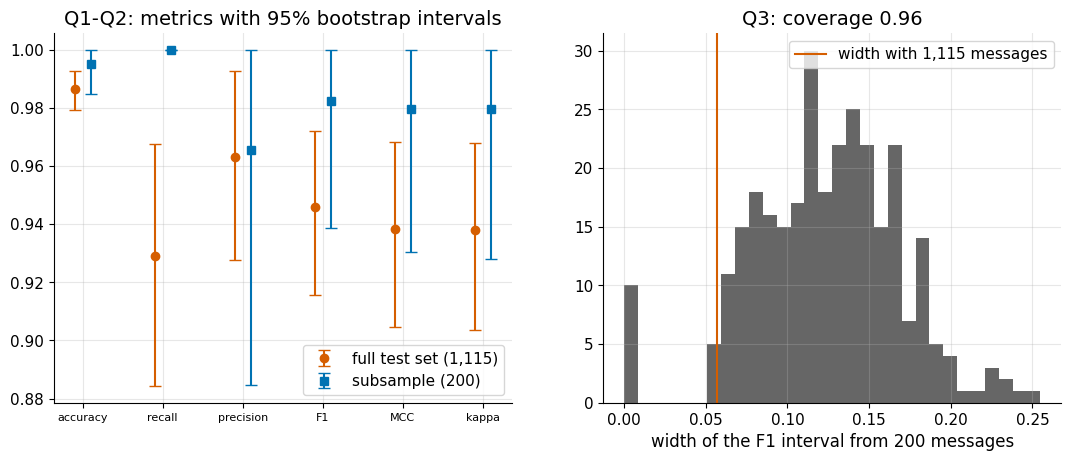

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); x = np.arange(len(ks)); axes[0].errorbar(x - 0.1, [base[k] for k in ks], yerr=[[base[k] - ci_full[k][0] for k in ks], [ci_full[k][1] - base[k] for k in ks]], fmt="o", color=HIGHLIGHT, capsize=4, label="full test set (1,115)"); axes[0].errorbar(x + 0.1, [m_sub[k] for k in ks], yerr=[[m_sub[k] - ci_sub[k][0] for k in ks], [ci_sub[k][1] - m_sub[k] for k in ks]], fmt="s", color=MAIN, capsize=4, label="subsample (200)"); axes[0].set_xticks(x); axes[0].set_xticklabels(ks, fontsize=8); axes[0].legend(); axes[0].set_title("Q1-Q2: metrics with 95% bootstrap intervals")
axes[1].hist(widths, bins=30, color=NEUTRAL); axes[1].axvline(ci_full["F1"][1] - ci_full["F1"][0], color=HIGHLIGHT, label="width with 1,115 messages"); axes[1].legend(); axes[1].set_xlabel("width of the F1 interval from 200 messages"); axes[1].set_title(f"Q3: coverage {hits / 300:.2f}")
plt.show()

### 12.8 Interpretation and decision (Example 4)
- On the 1,115 held-out SMS messages the filter has 131 hits, 5 false alarms, 10 misses and 969 correct passes: accuracy **0.987**, recall **0.929** (interval **0.884 to 0.968**), precision **0.963** (0.928 to 0.993), F1 **0.946** (**0.915 to 0.972**), MCC **0.938** and kappa **0.938**.
- A random subsample of 200 messages (about 25 spam) gives F1 0.982 with an interval of **0.939 to 1.000** (as wide as the full-set interval despite the ceiling at 1) and a recall of exactly 1.0 with a degenerate interval: with few positives the percentile bootstrap breaks down at the boundary.
- Over 300 random subsamples the bootstrap interval for F1 covers the full-test-set value **96 %** of the time with a mean width of **0.124**, about twice the width with all 1,115 messages.
- The F1-optimal threshold (1.3) and the MCC-optimal threshold (1.7) are close to the default 0 in performance (F1 0.952 against 0.946), so the default is already near-optimal.
- **Decision.** Report every metric with an interval and the number of positives behind it; a difference of 0.02 in F1 between two models on 141 spam messages is within noise.

## 13. Where it is used

### Statistics
- **Diagnostic accuracy and agreement statistics** (kappa for inter-rater reliability, the phi coefficient for $2\times2$ tables), informedness and markedness in the epidemiology of tests, bootstrap intervals for any statistic.

### Data science
- **Model comparison and reporting** (precision, recall and F1 for fraud, churn and lead scoring), imbalanced learning benchmarks (MCC, balanced accuracy), **retrieval and search evaluation** (precision and recall at $k$), named-entity recognition and detection (F1), annotator agreement.

### ML and AI
- **Safety and toxicity classifiers** evaluated by recall at a fixed precision, **evaluating LLM judges** against human labels (kappa, MCC), **RAG** retrieval metrics, leaderboards that must not be fooled by class imbalance, and the metrics monitored in production alongside calibration (10_06).

## 14. Common pitfalls and misconceptions

- **Reporting accuracy on imbalanced data:** use at least precision, recall and one prevalence-robust summary (balanced accuracy, $J$ or MCC) (Examples 1 and 2).
- **Trusting F1 when the negative class matters:** F1 ignores true negatives; "always positive" has F1 $=2\pi/(1+\pi)$ (Example 2).
- **Comparing metrics across datasets with different prevalence:** precision, F1, MCC and kappa all change with $\pi$ even for the same classifier (8.3).
- **Choosing a model by one metric and a threshold by another:** the threshold that maximises accuracy is not the one for F1 or MCC (Example 3).
- **Averaging F1 over folds or classes without thought:** the mean of F1s is not the F1 of the pooled data; micro, macro and weighted averages answer different questions (10_07).
- **Ignoring the uncertainty of a metric:** with 25 positives an F1 has an interval of $\pm0.1$ (Example 4); a difference of 0.02 between models is noise.
- **Maximising F1 when errors have costs:** use costs or F$_\beta$ (next lesson); F1 assumes a false alarm and a miss cost the same.
- **Using kappa or MCC as a goal for training:** they are not differentiable proxies for what the business wants; optimise a proper loss and choose the threshold afterwards.

## 15. Exercises

1. A classifier has TP = 45, FP = 15, FN = 30, TN = 910. Compute accuracy, precision, recall, specificity, F1, F$_2$, balanced accuracy, $J$, MCC and kappa.
2. For TPR 0.9 and FPR 0.1 compute F1 at prevalences 50 % and 1 %, and the prevalence at which F1 equals 0.5.
3. Show that the F1 of "always positive" equals $2\pi/(1+\pi)$ and find the prevalence above which it exceeds 0.9.
4. Two raters label 100 items: both say yes 40 times, both no 30 times, rater A yes/B no 20 times, A no/B yes 10 times. Compute the agreement and Cohen's kappa.
5. Using the SMS scores of Example 4, find the threshold that maximises F1 and the one that maximises MCC.
6. (Harder) Prove that MCC $=\sqrt{J\cdot\text{markedness}}$ from the definitions.

Solutions are at the end.

## 16. Summary table

| Metric | Question it answers | Ignores | Prevalence-dependent |
|---|---|---|---|
| Accuracy | share correct | which kind of error | yes |
| Recall | share of positives found | false alarms | no |
| Precision | share of alerts that are real | misses, TN | yes |
| F1 | balance of precision and recall | TN | yes |
| F$_\beta$ | same, with recall $\beta$ times as important | TN | yes |
| Balanced accuracy / $J$ | average over the two classes | prevalence | no |
| MCC | correlation of prediction and truth | nothing (all four cells) | yes |
| Kappa | agreement beyond chance | | yes |

## Solutions

In [26]:
m5 = metrics(45, 15, 30, 910, beta=2); print("1:", {k: round(float(v), 4) for k, v in m5.items()})
for p in (0.5, 0.01): print(f"2: prevalence {p}: F1 = {from_rates(0.9, 0.1, p)['F1']:.4f}")
pp = np.linspace(0.001, 0.999, 99_999); f1c = np.array([2 * p * 0.9 / (p * 1.9 + (1 - p) * 0.1) for p in pp]); print(f"   prevalence with F1 = 0.5: {pp[np.argmin(np.abs(f1c - 0.5))]:.4f} | 'always positive' exceeds F1 = 0.9 when 2 pi / (1 + pi) > 0.9, i.e. pi > {0.9 / (2 - 0.9):.4f}")
yy = metrics(40, 20, 10, 30); print(f"4: agreement {yy['accuracy']:.2f}; chance agreement {((40 + 20) * (40 + 10) + (30 + 10) * (30 + 20)) / 100 ** 2:.2f}; kappa {yy['kappa']:.4f}")
ths = np.linspace(-30, 60, 901); mf = [metrics(*cells(yte, sc > t_))["F1"] for t_ in ths]; mc = [metrics(*cells(yte, sc > t_))["MCC"] for t_ in ths]; print(f"5: threshold maximising F1: {ths[int(np.argmax(mf))]:.1f} (F1 {max(mf):.4f}); maximising MCC: {ths[int(np.argmax(mc))]:.1f} (MCC {max(mc):.4f}) | default threshold 0: F1 {base['F1']:.4f}, MCC {base['MCC']:.4f}")
print("6: MCC^2 = (TP TN - FP FN)^2 / ((TP + FP)(TP + FN)(TN + FP)(TN + FN)); J = (TP TN - FP FN) / (P N) and markedness = (TP TN - FP FN) / ((TP + FP)(TN + FN)); their product is the same ratio. Numerically:", round((45 * 910 - 15 * 30) ** 2 / ((60) * (75) * (925) * (940)), 6), "=", round(m5["J"] * m5["markedness"], 6))
assert abs(yy["kappa"] - 0.4) < 0.05 and abs(m5["MCC"] ** 2 - m5["J"] * m5["markedness"]) < 1e-12

1: {'accuracy': 0.955, 'recall': 0.6, 'specificity': 0.9838, 'precision': 0.75, 'NPV': 0.9681, 'F1': 0.6667, 'Fbeta': 0.625, 'balanced_accuracy': 0.7919, 'J': 0.5838, 'markedness': 0.7181, 'MCC': 0.6475, 'kappa': 0.6429}
2: prevalence 0.5: F1 = 0.9000
2: prevalence 0.01: F1 = 0.1525
   prevalence with F1 = 0.5: 0.0556 | 'always positive' exceeds F1 = 0.9 when 2 pi / (1 + pi) > 0.9, i.e. pi > 0.8182
4: agreement 0.70; chance agreement 0.50; kappa 0.4000


5: threshold maximising F1: 1.3 (F1 0.9524); maximising MCC: 1.7 (MCC 0.9464) | default threshold 0: F1 0.9458, MCC 0.9384
6: MCC^2 = (TP TN - FP FN)^2 / ((TP + FP)(TP + FN)(TN + FP)(TN + FN)); J = (TP TN - FP FN) / (P N) and markedness = (TP TN - FP FN) / ((TP + FP)(TN + FN)); their product is the same ratio. Numerically: 0.419206 = 0.419206


**1.** Accuracy **0.955**, precision **0.75**, recall **0.60**, specificity **0.9838**, F1 **0.667**, F$_2$ **0.625**, balanced accuracy **0.792**, $J$ **0.584**, MCC **0.648**, kappa **0.643**.

**2.** F1 $=\dfrac{2\pi\cdot0.9}{1.9\pi+0.1(1-\pi)}$: **0.90** at $\pi=0.5$ and **0.1525** at $\pi=0.01$; F1 equals 0.5 at $\pi\approx$ **0.056**.

**3.** TP $=\pi$, FP $=1-\pi$, FN $=0$ give $F_1=2\pi/(2\pi+1-\pi)=2\pi/(1+\pi)$; it exceeds 0.9 when $\pi>0.9/1.1=$ **0.818**.

**4.** Agreement $p_o=0.70$; chance agreement $p_e=0.6\cdot0.5+0.4\cdot0.5=0.50$; kappa $=0.2/0.5=$ **0.40**.

**5.** The F1-maximising threshold is **1.3** (F1 0.9524) and the MCC-maximising one **1.7** (MCC 0.9464), against F1 0.9458 and MCC 0.9384 at the default 0.

**6.** $J=\dfrac{TP\,TN-FP\,FN}{PN}$ and markedness $=\dfrac{TP\,TN-FP\,FN}{(TP+FP)(TN+FN)}$; their product is $\dfrac{(TP\,TN-FP\,FN)^2}{(TP+FP)(TP+FN)(TN+FP)(TN+FN)}=\mathrm{MCC}^2$. Numerically 0.419206 for exercise 1.